# 第 5 章 特殊分布随机数的抽样 —— 代码实现

对应笔记 `docs/mc/ch05.md`。七个实验：逆变换（指数/柯西）、圆盘均匀（拒绝法与半径陷阱）、一般舍选（Beta(2,2)）、组合法（拉普拉斯）、Box-Muller、Erlang 与 Beta、Alias 方法。

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pathlib import Path

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False

FIGDIR = Path(r"E:/Desktop/深度学习/mynotes/docs/mc/images/ch05")
FIGDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIGDIR / name, dpi=150, bbox_inches="tight")

rng = np.random.default_rng(2028)

## 5.1 逆变换法：指数与柯西

$X=F^{-1}(U)$。指数（$\lambda=1$）：$X=-\ln(1-U)$；柯西：$X=\tan(\pi(U-\tfrac12))$（重尾：无均值）。

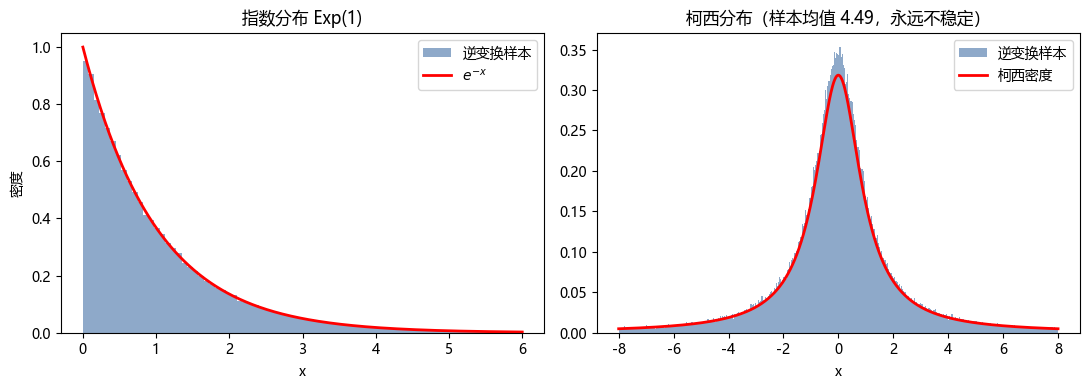

In [2]:
u = rng.random(200_000)
X_exp = -np.log(1 - u)
X_cauchy = np.tan(np.pi * (u - 0.5))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(0, 6, 400)
axes[0].hist(X_exp, bins=80, range=(0, 6), density=True, color="#8ea9c9", label="逆变换样本")
axes[0].plot(xx, np.exp(-xx), "r-", lw=2, label=r"$e^{-x}$")
axes[0].set(title="指数分布 Exp(1)", xlabel="x", ylabel="密度"); axes[0].legend()

xc = np.linspace(-8, 8, 800)
axes[1].hist(X_cauchy, bins=400, range=(-8, 8), density=True, color="#8ea9c9", label="逆变换样本")
axes[1].plot(xc, stats.cauchy.pdf(xc), "r-", lw=2, label="柯西密度")
axes[1].set(title=f"柯西分布（样本均值 {X_cauchy.mean():.2f}，永远不稳定）", xlabel="x")
axes[1].legend()
fig.tight_layout(); save(fig, "out-inverse.png"); plt.show()

## 5.2 圆盘均匀：拒绝法与半径陷阱

三种做法对比：拒绝法（扔方形、留圆内）；错误做法 $r\sim U(0,1)$（中心堆积）；正确极坐标 $r=\sqrt{U}$。

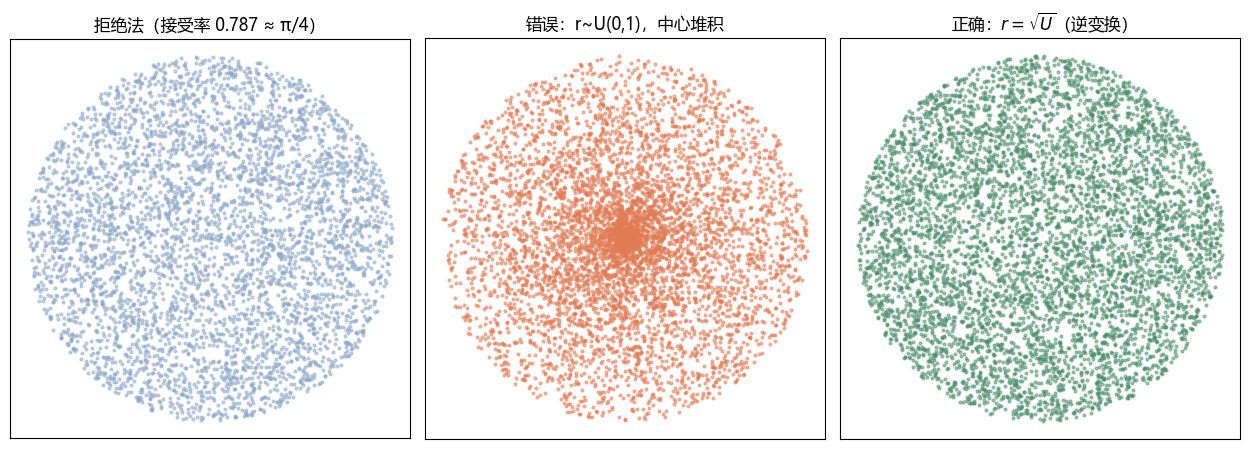

拒绝法接受率 0.7868（理论 π/4 = 0.7854）


In [3]:
n = 6000
xy = rng.random((n, 2)) * 2 - 1
keep = (xy**2).sum(axis=1) <= 1
acc_rate = keep.mean()
r_u = rng.random(n)                       # 错误：半径均匀
r_ok = np.sqrt(rng.random(n))             # 正确：CDF 反函数
th = rng.random(n) * 2 * np.pi

fig, axes = plt.subplots(1, 3, figsize=(12.6, 4.4))
axes[0].scatter(xy[keep, 0], xy[keep, 1], s=4, alpha=0.5, color="#8ea9c9")
axes[0].set(title=f"拒绝法（接受率 {acc_rate:.3f} ≈ π/4）", aspect="equal", xticks=[], yticks=[])
axes[1].scatter(r_u*np.cos(th), r_u*np.sin(th), s=4, alpha=0.5, color="#e07b54")
axes[1].set(title="错误：r~U(0,1)，中心堆积", aspect="equal", xticks=[], yticks=[])
axes[2].scatter(r_ok*np.cos(th), r_ok*np.sin(th), s=4, alpha=0.5, color="#4c8f6d")
axes[2].set(title=r"正确：$r=\sqrt{U}$（逆变换）", aspect="equal", xticks=[], yticks=[])
fig.tight_layout(); save(fig, "out-disk.png"); plt.show()
print(f"拒绝法接受率 {acc_rate:.4f}（理论 π/4 = {np.pi/4:.4f}）")

## 5.2 一般舍选：Beta(2,2)

目标 $f(x)=6x(1-x)$（峰 1.5），包络 $g=U(0,1)$，$M=1.5$。理论接受率 $1/M=2/3$。

接受率 0.6649（理论 2/3 = 0.6667）


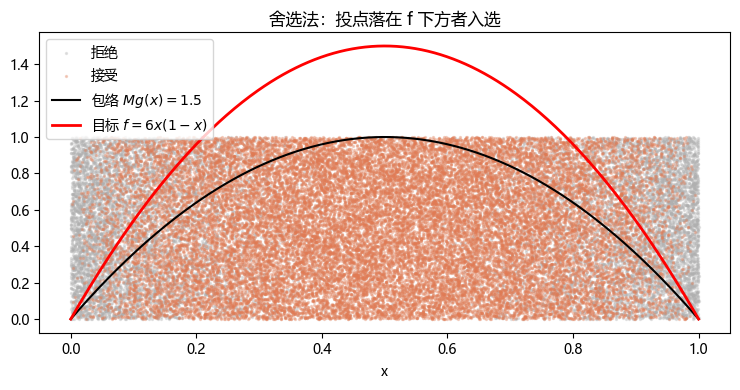

入选样本均值 0.5006（理论 0.5），方差 0.0498（理论 0.05）


In [4]:
N = 300_000
x = rng.random(N)
acc = rng.random(N) * 1.5 <= 6 * x * (1 - x)   # U·M ≤ f(x)
print(f"接受率 {acc.mean():.4f}（理论 2/3 = {2/3:.4f}）")

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(x[~acc][::7], rng.random((~acc).sum())[::7], s=2, alpha=0.3, color="#b0b0b0", label="拒绝")
ax.scatter(x[acc][::7], rng.random(acc.sum())[::7], s=2, alpha=0.3, color="#e07b54", label="接受")
xx = np.linspace(0, 1, 400)
ax.plot(xx, 6*xx*(1-xx)/1.5, "k-", lw=1.5, label="包络 $Mg(x)=1.5$")
ax.plot(xx, 6*xx*(1-xx), "r-", lw=2, label="目标 $f=6x(1-x)$")
ax.set(xlabel="x", ylabel="", title="舍选法：投点落在 f 下方者入选")
ax.legend(); fig.tight_layout(); save(fig, "out-rejection.png"); plt.show()

xs = x[acc]
print(f"入选样本均值 {xs.mean():.4f}（理论 0.5），方差 {xs.var():.4f}（理论 0.05）")

## 5.3 组合法：拉普拉斯（双指数）

$f=\frac12 e^{-|x|}$：以 ½ 抽 $+Exp(1)$、以 ½ 抽 $-Exp(1)$。

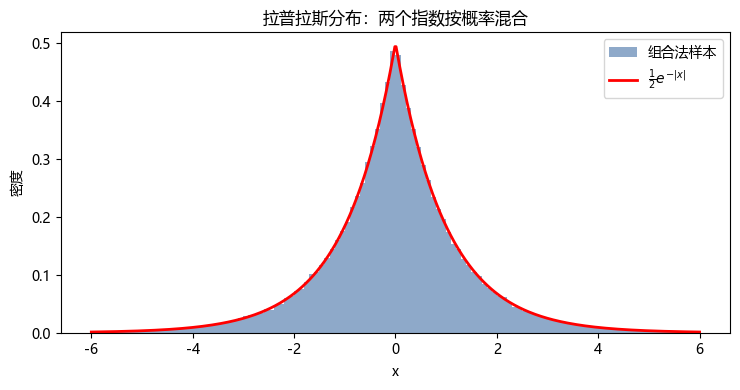

In [5]:
u = rng.random(200_000)
E = -np.log(1 - rng.random(200_000))
X = np.where(u < 0.5, E, -E)

fig, ax = plt.subplots(figsize=(7.5, 4))
xx = np.linspace(-6, 6, 500)
ax.hist(X, bins=120, range=(-6, 6), density=True, color="#8ea9c9", label="组合法样本")
ax.plot(xx, 0.5*np.exp(-np.abs(xx)), "r-", lw=2, label=r"$\frac{1}{2}e^{-|x|}$")
ax.set(title="拉普拉斯分布：两个指数按概率混合", xlabel="x", ylabel="密度")
ax.legend(); fig.tight_layout(); save(fig, "out-laplace.png"); plt.show()

## 5.4 Box–Muller

$R=\sqrt{-2\ln U_1}$（瑞利），$\Theta=2\pi U_2$；$Z_1=R\cos\Theta,\ Z_2=R\sin\Theta$ 独立标准正态。左：直方图 vs 密度；右：\((Z_1,Z_2)\) 圆对称。

Z1: 均值 -0.0018，方差 1.0033，与 Z2 相关系数 +0.0011


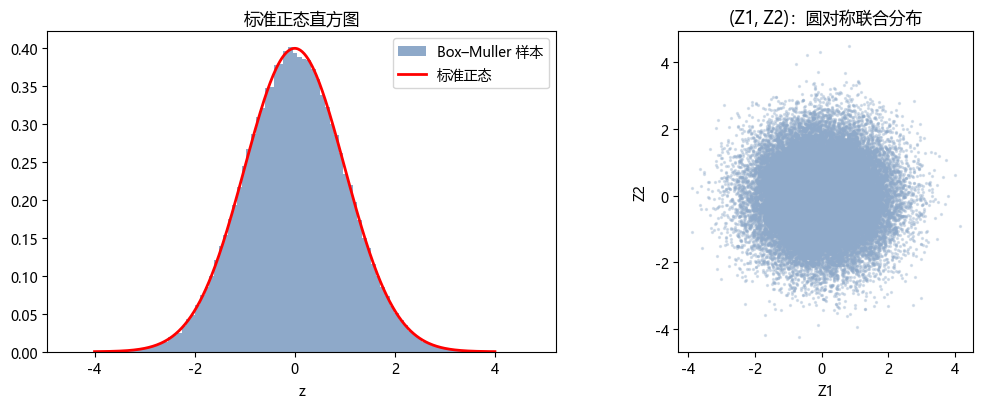

In [6]:
n = 200_000
u1, u2 = rng.random(n), rng.random(n)
R = np.sqrt(-2 * np.log(u1))
Z1, Z2 = R*np.cos(2*np.pi*u2), R*np.sin(2*np.pi*u2)
print(f"Z1: 均值 {Z1.mean():.4f}，方差 {Z1.var():.4f}，与 Z2 相关系数 {np.corrcoef(Z1, Z2)[0,1]:+.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
xx = np.linspace(-4, 4, 400)
axes[0].hist(Z1, bins=100, density=True, color="#8ea9c9", label="Box–Muller 样本")
axes[0].plot(xx, np.exp(-xx**2/2)/np.sqrt(2*np.pi), "r-", lw=2, label="标准正态")
axes[0].set(title="标准正态直方图", xlabel="z"); axes[0].legend()
axes[1].scatter(Z1[::5], Z2[::5], s=2, alpha=0.3, color="#8ea9c9")
axes[1].set(title="(Z1, Z2)：圆对称联合分布", aspect="equal", xlabel="Z1", ylabel="Z2")
fig.tight_layout(); save(fig, "out-boxmuller.png"); plt.show()

## 5.5 Erlang 与 Beta

$Erlang(3)=Exp(1)$ 之和（整数形状 Γ 的卷积性质）；$Beta(2,5)=\frac{G_1}{G_1+G_2}$，$G_1\sim Γ(2),\ G_2\sim Γ(5)$（均可用指数和构造）。

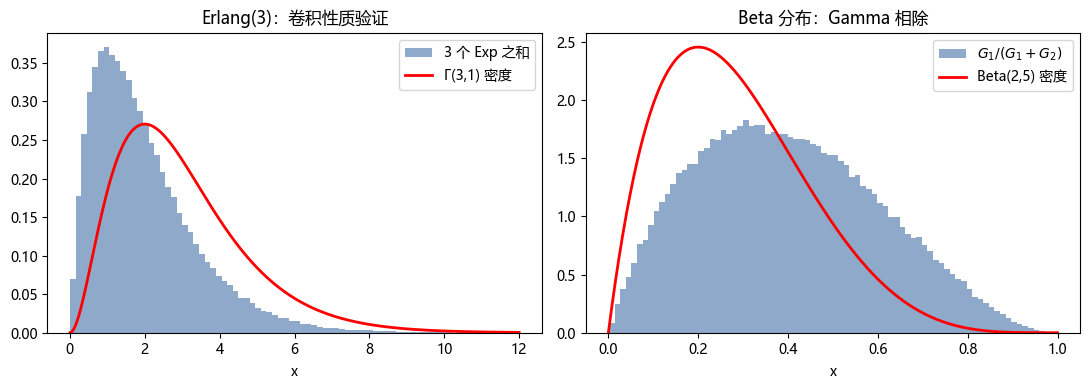

In [7]:
n = 200_000
E = -np.log(1 - rng.random((n, 5)))   # 5 列独立 Exp(1)
G1 = E[:, :2].sum(axis=1)
G2 = E[:, 2:].sum(axis=1)
X_erlang = G1
X_beta = G1 / (G1 + G2)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
xx = np.linspace(0, 12, 500)
axes[0].hist(X_erlang, bins=80, range=(0, 12), density=True, color="#8ea9c9", label="3 个 Exp 之和")
axes[0].plot(xx, stats.gamma.pdf(xx, 3), "r-", lw=2, label="Γ(3,1) 密度")
axes[0].set(title="Erlang(3)：卷积性质验证", xlabel="x"); axes[0].legend()
xx = np.linspace(0, 1, 500)
axes[1].hist(X_beta, bins=80, density=True, color="#8ea9c9", label=r"$G_1/(G_1+G_2)$")
axes[1].plot(xx, stats.beta.pdf(xx, 2, 5), "r-", lw=2, label="Beta(2,5) 密度")
axes[1].set(title="Beta 分布：Gamma 相除", xlabel="x"); axes[1].legend()
fig.tight_layout(); save(fig, "out-gamma-beta.png"); plt.show()

## 5.6 Alias 方法：O(1) 的离散抽样

不均匀骰子 $P(i)\propto i$：构造概率表 q 与别名表 alias（一次 O(K)），之后每次抽取只需一次均匀整数 + 一次均匀比较。

q    = [0.286 0.571 0.857 1.    0.857 0.429]
alias= [6 6 6 1 4 5]


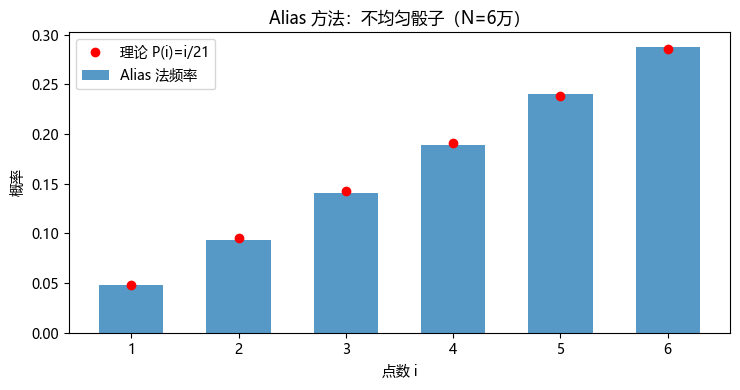

最大偏差: 0.0021190476190476315


In [8]:
def alias_setup(p):
    K = len(p)
    q = np.asarray(p, float) * K
    alias = np.zeros(K, dtype=int)
    small = [i for i in range(K) if q[i] < 1]
    large = [i for i in range(K) if q[i] >= 1]
    while small and large:
        s, l = small.pop(), large.pop()
        alias[s] = l
        q[l] -= 1 - q[s]
        (large if q[l] >= 1 else small).append(l)
    return q, alias

def alias_draw(q, alias, n):
    K = len(q)
    i = rng.integers(0, K, n)
    return np.where(rng.random(n) < q[i], i, alias[i]) + 1

p = np.arange(1, 7) / 21
q, alias = alias_setup(p)
print("q    =", np.round(q, 3))
print("alias=", alias + 1)
faces = alias_draw(q, alias, 60_000)
vals, cnts = np.unique(faces, return_counts=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.bar(vals, cnts/60_000, width=0.6, alpha=0.75, label="Alias 法频率")
ax.plot(vals, p, "ro", ms=6, label=r"理论 P(i)=i/21")
ax.set(xlabel="点数 i", ylabel="概率", title="Alias 方法：不均匀骰子（N=6万）")
ax.legend(); fig.tight_layout(); save(fig, "out-alias.png"); plt.show()
print("最大偏差:", np.abs(cnts/60_000 - p).max())